# Calibrating and validating fade margins

A fade margin is an upper quantile forecast of the path-loss deviation `y` from the link's anchor, the previous-hour mean. This notebook builds the margin in the usual ways and tests each one the way a quantile forecast is tested, instead of comparing mean margins at unmatched coverage.

* **Base predictors**, both on rung H4 of `12_History_Features`: a LightGBM regression, with one margin on top of it, and LightGBM quantile models at the target level.
* **Calibrations of the shift**, all from earlier packets only: one pooled shift (split conformal, as in conformalised quantile regression), one shift per group, a recency-weighted shift, and adaptive conformal inference run per link. The groups are spreading factor x working hours, and the same split by recent-spread tercile, which makes the margin a lookup table of the state.
* **Rolling origin.** The shift of a window comes only from the validation folds before it, so validation folds 1 to 4 and the hold-out are five test windows.
* **Scores.** Coverage overall and by state, the mean margin, and the pinball loss, the consistent score of a quantile. Intervals are 95 % by resampling days, because packets of one day are not independent.
* **Backtests.** The chance of a miss right after a miss against after a covered packet (Christoffersen), and a logistic regression of the misses on the previous miss and the state, with errors clustered by day (conditional coverage).

The three target levels are 90, 95 and 99 %. The 99 % level carries the detailed tables.

In [1]:
import json
import time
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from history_features import RUNGS
from margin_tools import (pinball, shift_pooled, shift_groups, shift_weighted, aci, spread_groups, day_codes, boot_stat,
                          transitions, clustering_ratio, christoffersen_independence, dynamic_binary_test)

RANDOM_STATE = 42
TARGETS = (0.90, 0.95, 0.99)
HALF_LIFE = 30          # days, recency-weighted shift
GAMMA_DIVISOR = 20      # adaptive conformal inference: step size (1 - target) / 20

In [2]:
# The rows, folds and inputs of notebooks 13 to 15
train = pd.read_csv("Data_Files/history_train.csv")
test = pd.read_csv("Data_Files/history_test.csv")
d = pd.concat([train, test], ignore_index=True)
d["t"] = pd.to_datetime(d["t"], utc=True)
d = d.sort_values("t").reset_index(drop=True)
fold = d["fold"].to_numpy()
H = {k.split()[0]: v for k, v in RUNGS.items()}
ok = (d["y"].notna() & d[H["H7"]].notna().all(axis=1)).to_numpy()          # an anchor and a complete input
y = d["y"].to_numpy()
X_all = d[H["H7"]].copy()
X = X_all.fillna(X_all[ok & (fold < 9)].median())[H["H4"]].to_numpy()       # rung H4: link history, channel, clock, SF
best = json.load(open("CV_Results/history_best_params.json"))["LGBM"]
link, sf, work, s20 = d["device_id"].to_numpy(), d["SF"].to_numpy().astype(int), d["work"].to_numpy().astype(int), d["s20"].to_numpy()
day = day_codes(d["t"])
print(f"packets with an anchor: {ok.sum():,}; validation folds 0-4: {(ok & (fold >= 0) & (fold < 9)).sum():,}; hold-out: {(ok & (fold == 9)).sum():,}")

packets with an anchor: 2,658,662; validation folds 0-4: 1,773,285; hold-out: 531,983


In [3]:
# Base predictors: out-of-fold for validation folds 0-4 (each fitted on the folds before it) and a fit on all training rows for the hold-out
def oof_and_test(make):
    p = np.full(len(d), np.nan)
    for k in range(5):
        tr, va = ok & (fold < k), ok & (fold == k)
        p[va] = make().fit(X[tr], y[tr]).predict(X[va])
    tr, ev = ok & (fold < 9), ok & (fold == 9)
    p[ev] = make().fit(X[tr], y[tr]).predict(X[ev])
    return p

params = dict(subsample_freq=1, random_state=RANDOM_STATE, n_jobs=8, verbose=-1, **best)      # 8 threads: LightGBM stalls when oversubscribed
t0 = time.time()
base = {"reg": oof_and_test(lambda: lgb.LGBMRegressor(**params))}
for tau in TARGETS:
    base[("q", tau)] = oof_and_test(lambda: lgb.LGBMRegressor(objective="quantile", alpha=tau, **params))
print(f"one regression and {len(TARGETS)} quantile models, each fitted six times: {time.time() - t0:.0f} s")

one regression and 3 quantile models, each fitted six times: 717 s


In [4]:
# Margins above the anchor for every window, target and method
windows = [1, 2, 3, 4, 9]

def state_codes(rows, cut):
    g1 = (sf[rows] - 7) * 2 + work[rows]                    # spreading factor x working hours
    return g1, g1 * 3 + spread_groups(s20[rows], cut)       # and the same split by recent-spread tercile

def calibrate(b, tau, cal, te, cut, half_life=HALF_LIFE, gamma_divisor=GAMMA_DIVISOR):
    """Base threshold b plus a shift from the scores of the earlier packets cal, five ways, for the packets te."""
    score = y[cal] - b[cal]
    g1_cal, g2_cal = state_codes(cal, cut)
    g1_te, g2_te = state_codes(te, cut)
    age = (d["t"].iloc[te].min() - d["t"].iloc[cal]).dt.total_seconds().to_numpy() / 86400
    out = {"pooled": b[te] + shift_pooled(score, tau),
           "SF x hours": b[te] + shift_groups(score, g1_cal, g1_te, tau),
           "state table": b[te] + shift_groups(score, g2_cal, g2_te, tau),
           "recency": b[te] + shift_weighted(score, age, tau, half_life)}
    m = np.empty(len(te))
    for l in np.unique(link[te]):                           # one adaptive sequence per link, in time order
        i = np.flatnonzero(link[te] == l)
        m[i] = aci(b[te][i], y[te][i], score, tau, (1 - tau) / gamma_divisor)
    out["ACI"] = m
    return out

margin, cuts, rows_of = {}, {}, {}
t0 = time.time()
for w in windows:
    te = np.flatnonzero(ok & (fold == w))
    cal = np.flatnonzero(ok & (fold >= 0) & (fold < w))     # earlier validation folds only
    rows_of[w], cuts[w] = te, np.quantile(s20[cal], [1 / 3, 2 / 3])
    for tau in TARGETS:
        for kind in ("reg", "q"):
            b = base["reg"] if kind == "reg" else base[("q", tau)]
            for name, m in calibrate(b, tau, cal, te, cuts[w]).items():
                margin[(tau, w, f"{kind} {name}")] = m
    print(f"window {w}: {len(te):,} packets, calibrated on {len(cal):,}  [{time.time() - t0:.0f} s]")
methods = [f"{kind} {name}" for kind in ("reg", "q") for name in ("pooled", "SF x hours", "state table", "recency", "ACI")]

window 1: 354,619 packets, calibrated on 354,701  [5 s]


window 2: 354,679 packets, calibrated on 709,320  [11 s]


window 3: 354,691 packets, calibrated on 1,063,999  [18 s]


window 4: 354,595 packets, calibrated on 1,418,690  [26 s]


window 9: 531,983 packets, calibrated on 1,773,285  [37 s]


In [5]:
# Coverage, mean margin and pinball loss, overall and by state: hours, recent spread, spreading factor, link
def summarize(w, tau, method):
    te, m = rows_of[w], margin[(tau, w, method)]
    miss, loss = y[te] > m, pinball(y[te], m, tau)
    labels = {"all": np.zeros(len(te), int), "hours": work[te], "spread": spread_groups(s20[te], cuts[w]), "SF": sf[te], "link": link[te]}
    return [dict(tau=tau, window=w, method=method, group_type=gt, group=str(g), n=int(sel.sum()), coverage=1 - miss[sel].mean(), margin=m[sel].mean(), pinball=loss[sel].mean())
            for gt, lab in labels.items() for g in np.unique(lab) for sel in [lab == g]]

table = pd.DataFrame([r for tau in TARGETS for w in windows for m in methods for r in summarize(w, tau, m)])
table.to_csv("CV_Results/margin_calibration.csv", index=False)

for tau in TARGETS:
    t = table[table.tau == tau]
    overall = t[t.group_type == "all"]
    worst = t[(t.group_type != "all") & (t.n >= 1000)].groupby(["method", "window"]).coverage.min().unstack()
    print(f"target {tau}: coverage overall, lowest coverage over the states with 1000 packets or more, and mean pinball loss, by test window")
    display(pd.concat({"coverage": overall.pivot(index="method", columns="window", values="coverage").loc[methods],
                       "worst state": worst.loc[methods],
                       "pinball": overall.pivot(index="method", columns="window", values="pinball").loc[methods]}, axis=1).round(4))

target 0.9: coverage overall, lowest coverage over the states with 1000 packets or more, and mean pinball loss, by test window


coverage                                 worst state          \
window                 1       2       3       4       9           1       2   
method                                                                         
reg pooled        0.9040  0.8912  0.9063  0.9194  0.9258      0.8310  0.8206   
reg SF x hours    0.9051  0.8923  0.9073  0.9145  0.9017      0.8951  0.8251   
reg state table   0.9052  0.8925  0.9068  0.9122  0.8928      0.8959  0.8291   
reg recency       0.9033  0.8902  0.9089  0.9182  0.9111      0.8308  0.8198   
reg ACI           0.9001  0.9000  0.9000  0.9002  0.9001      0.8283  0.8262   
q pooled          0.9098  0.8999  0.9095  0.9154  0.8996      0.9023  0.8580   
q SF x hours      0.9096  0.8998  0.9096  0.9153  0.8987      0.9007  0.8582   
q state table     0.9095  0.9000  0.9094  0.9146  0.8957      0.9002  0.8592   
q recency         0.9103  0.8973  0.9086  0.9113  0.8867      0.9026  0.8563   
q ACI             0.9001  0.9000  0.8999  0.9001  0.9000      0.8928  0.8932   

                                        pinball                          \
window                3       4       9       1       2       3       4   
method                                                                    
reg pooled       0.8310  0.8287  0.8539  0.4337  0.4695  0.4957  0.3868   
reg SF x hours   0.8860  0.8888  0.8449  0.4109  0.4452  0.4720  0.3640   
reg state table  0.8879  0.8976  0.8710  0.4103  0.4437  0.4712  0.3620   
reg recency      0.8328  0.8279  0.8322  0.4337  0.4696  0.4960  0.3865   
reg ACI          0.8274  0.8239  0.8131  0.4292  0.4541  0.4853  0.3768   
q pooled         0.8998  0.9005  0.8855  0.3848  0.4102  0.4387  0.3443   
q SF x hours     0.9001  0.9024  0.8853  0.3848  0.4102  0.4386  0.3442   
q state table    0.9006  0.9017  0.8842  0.3849  0.4101  0.4387  0.3440   
q recency        0.8994  0.8978  0.8729  0.3848  0.4103  0.4386  0.3438   
q ACI            0.8925  0.8848  0.8961  0.3837  0.4074  0.4366  0.3420   

                         
window                9  
method                   
reg pooled       0.2943  
reg SF x hours   0.2801  
reg state table  0.2781  
reg recency      0.2914  
reg ACI          0.2851  
q pooled         0.2734  
q SF x hours     0.2734  
q state table    0.2734  
q recency        0.2739  
q ACI            0.2725

target 0.95: coverage overall, lowest coverage over the states with 1000 packets or more, and mean pinball loss, by test window


coverage                                 worst state          \
window                 1       2       3       4       9           1       2   
method                                                                         
reg pooled        0.9516  0.9424  0.9536  0.9639  0.9759      0.8679  0.8596   
reg SF x hours    0.9535  0.9423  0.9550  0.9598  0.9541      0.9411  0.8775   
reg state table   0.9534  0.9427  0.9544  0.9575  0.9473      0.9409  0.8829   
reg recency       0.9507  0.9419  0.9555  0.9638  0.9673      0.8671  0.8591   
reg ACI           0.9501  0.9500  0.9500  0.9502  0.9502      0.8666  0.8656   
q pooled          0.9573  0.9505  0.9569  0.9611  0.9531      0.9478  0.9174   
q SF x hours      0.9570  0.9506  0.9569  0.9611  0.9523      0.9484  0.9177   
q state table     0.9570  0.9505  0.9568  0.9603  0.9501      0.9481  0.9185   
q recency         0.9576  0.9487  0.9559  0.9584  0.9444      0.9480  0.9159   
q ACI             0.9501  0.9500  0.9499  0.9501  0.9501      0.9467  0.9448   

                                        pinball                          \
window                3       4       9       1       2       3       4   
method                                                                    
reg pooled       0.8684  0.8672  0.9302  0.3075  0.3352  0.3721  0.2687   
reg SF x hours   0.9402  0.9417  0.9071  0.2674  0.2940  0.3303  0.2339   
reg state table  0.9429  0.9454  0.9314  0.2665  0.2913  0.3291  0.2315   
reg recency      0.8706  0.8670  0.9159  0.3075  0.3354  0.3725  0.2686   
reg ACI          0.8652  0.8631  0.8911  0.3031  0.3172  0.3394  0.2572   
q pooled         0.9482  0.9529  0.9402  0.2428  0.2593  0.2959  0.2137   
q SF x hours     0.9501  0.9541  0.9400  0.2427  0.2593  0.2958  0.2136   
q state table    0.9504  0.9532  0.9412  0.2427  0.2591  0.2959  0.2135   
q recency        0.9479  0.9513  0.9333  0.2428  0.2594  0.2958  0.2133   
q ACI            0.9443  0.9403  0.9463  0.2417  0.2556  0.2755  0.2118   

                         
window                9  
method                   
reg pooled       0.1944  
reg SF x hours   0.1756  
reg state table  0.1724  
reg recency      0.1882  
reg ACI          0.1795  
q pooled         0.1679  
q SF x hours     0.1679  
q state table    0.1677  
q recency        0.1680  
q ACI            0.1668

target 0.99: coverage overall, lowest coverage over the states with 1000 packets or more, and mean pinball loss, by test window


coverage                                 worst state          \
window                 1       2       3       4       9           1       2   
method                                                                         
reg pooled        0.9906  0.9879  0.9894  0.9941  0.9985      0.9442  0.9364   
reg SF x hours    0.9911  0.9858  0.9907  0.9929  0.9933      0.9838  0.9541   
reg state table   0.9909  0.9865  0.9902  0.9921  0.9912      0.9828  0.9586   
reg recency       0.9904  0.9877  0.9899  0.9948  0.9976      0.9432  0.9355   
reg ACI           0.9901  0.9900  0.9900  0.9907  0.9905      0.9405  0.9398   
q pooled          0.9915  0.9898  0.9913  0.9931  0.9926      0.9862  0.9778   
q SF x hours      0.9918  0.9900  0.9914  0.9932  0.9919      0.9881  0.9782   
q state table     0.9917  0.9901  0.9914  0.9927  0.9911      0.9880  0.9786   
q recency         0.9914  0.9896  0.9912  0.9930  0.9908      0.9861  0.9774   
q ACI             0.9901  0.9901  0.9901  0.9901  0.9901      0.9858  0.9860   

                                        pinball                          \
window                3       4       9       1       2       3       4   
method                                                                    
reg pooled       0.9421  0.9457  0.9912  0.1288  0.1372  0.1897  0.1137   
reg SF x hours   0.9850  0.9873  0.9768  0.0872  0.0997  0.1482  0.0776   
reg state table  0.9849  0.9881  0.9869  0.0865  0.0973  0.1466  0.0755   
reg recency      0.9449  0.9516  0.9870  0.1287  0.1374  0.1896  0.1165   
reg ACI          0.9379  0.9389  0.9740  0.1285  0.1323  0.1358  0.1034   
q pooled         0.9843  0.9888  0.9866  0.0776  0.0815  0.1241  0.0652   
q SF x hours     0.9846  0.9907  0.9862  0.0769  0.0811  0.1236  0.0650   
q state table    0.9846  0.9906  0.9879  0.0770  0.0810  0.1234  0.0649   
q recency        0.9842  0.9887  0.9847  0.0776  0.0815  0.1241  0.0652   
q ACI            0.9863  0.9869  0.9864  0.0770  0.0792  0.0825  0.0643   

                         
window                9  
method                   
reg pooled       0.0857  
reg SF x hours   0.0614  
reg state table  0.0583  
reg recency      0.0762  
reg ACI          0.0631  
q pooled         0.0520  
q SF x hours     0.0519  
q state table    0.0516  
q recency        0.0517  
q ACI            0.0513

In [6]:
# Hold-out, 99 %: coverage by state with 95 % intervals from resampling days
w, tau = 9, 0.99
te = rows_of[w]
dd = pd.factorize(day[te])[0]
states = {("all", "all"): np.ones(len(te), bool)}
for gt, lab in (("hours", work[te]), ("spread", spread_groups(s20[te], cuts[w])), ("SF", sf[te]), ("link", link[te])):
    for g in np.unique(lab):
        if (lab == g).sum() >= 1000:
            states[(gt, str(g))] = lab == g
rows = []
for method in methods:
    miss = (y[te] > margin[(tau, w, method)]).astype(float)
    for (gt, g), sel in states.items():
        cov, lo, hi = boot_stat(dd, np.column_stack([miss * sel, sel]), lambda T: 1 - T[:, 0] / T[:, 1])
        rows.append(dict(method=method, group_type=gt, group=g, n=int(sel.sum()), coverage=cov, lo=lo, hi=hi))
holdout = pd.DataFrame(rows)
holdout.to_csv("CV_Results/margin_holdout_states.csv", index=False)
print("hold-out coverage at the 99 % target by state (hours: 1 = working hours; spread: 0 calm, 1 middle, 2 volatile)")
display(holdout.pivot_table(index=["group_type", "group"], columns="method", values="coverage", sort=False)[methods].round(4))
below = holdout[holdout.hi < tau].groupby("method").size().reindex(methods, fill_value=0)
print("states whose whole interval lies below the target:")
display(below.to_frame("count").T)

hold-out coverage at the 99 % target by state (hours: 1 = working hours; spread: 0 calm, 1 middle, 2 volatile)


method            reg pooled  reg SF x hours  reg state table  reg recency  \
group_type group                                                             
all        all        0.9985          0.9933           0.9912       0.9976   
hours      0          0.9998          0.9942           0.9923       0.9996   
           1          0.9955          0.9910           0.9886       0.9931   
spread     0          0.9997          0.9961           0.9924       0.9993   
           1          0.9990          0.9937           0.9907       0.9982   
           2          0.9912          0.9768           0.9869       0.9870   
SF         7          0.9986          0.9972           0.9973       0.9978   
           8          0.9985          0.9917           0.9881       0.9977   
           9          0.9984          0.9911           0.9895       0.9970   
           10         0.9987          0.9930           0.9901       0.9980   
link       ED0        0.9983          0.9937           0.9914       0.9976   
           ED1        0.9989          0.9950           0.9935       0.9983   
           ED2        0.9967          0.9879           0.9873       0.9950   
           ED3        0.9998          0.9954           0.9928       0.9995   
           ED4        0.9985          0.9941           0.9906       0.9977   
           ED5        0.9990          0.9937           0.9917       0.9977   

method            reg ACI  q pooled  q SF x hours  q state table  q recency  \
group_type group                                                              
all        all     0.9905    0.9926        0.9919         0.9911     0.9908   
hours      0       0.9946    0.9936        0.9926         0.9917     0.9916   
           1       0.9810    0.9903        0.9902         0.9896     0.9891   
spread     0       0.9938    0.9941        0.9932         0.9918     0.9923   
           1       0.9904    0.9921        0.9915         0.9909     0.9904   
           2       0.9740    0.9866        0.9862         0.9883     0.9847   
SF         7       0.9932    0.9933        0.9941         0.9937     0.9911   
           8       0.9943    0.9927        0.9888         0.9879     0.9905   
           9       0.9802    0.9896        0.9918         0.9907     0.9884   
           10      0.9944    0.9948        0.9928         0.9921     0.9933   
link       ED0     0.9904    0.9935        0.9929         0.9920     0.9923   
           ED1     0.9910    0.9938        0.9932         0.9922     0.9923   
           ED2     0.9901    0.9895        0.9887         0.9883     0.9873   
           ED3     0.9909    0.9928        0.9921         0.9913     0.9907   
           ED4     0.9904    0.9927        0.9912         0.9901     0.9902   
           ED5     0.9904    0.9934        0.9932         0.9926     0.9923   

method             q ACI  
group_type group          
all        all    0.9901  
hours      0      0.9906  
           1      0.9887  
spread     0      0.9906  
           1      0.9904  
           2      0.9864  
SF         7      0.9905  
           8      0.9901  
           9      0.9880  
           10     0.9917  
link       ED0    0.9901  
           ED1    0.9901  
           ED2    0.9899  
           ED3    0.9902  
           ED4    0.9900  
           ED5    0.9901

states whose whole interval lies below the target:


method,reg pooled,reg SF x hours,reg state table,reg recency,reg ACI,q pooled,q SF x hours,q state table,q recency,q ACI
count,0,2,4,1,3,1,2,3,4,3


In [7]:
# Paired contrasts between methods, 99 %: differences with 95 % intervals from resampling days
contrasts = [("q pooled", "reg pooled"), ("q pooled", "reg SF x hours"), ("q pooled", "reg state table"), ("q SF x hours", "q pooled"),
             ("q recency", "q pooled"), ("q ACI", "q pooled"), ("reg ACI", "reg pooled")]
tau = 0.99
rows = []
for w in windows:
    te = rows_of[w]
    dd = pd.factorize(day[te])[0]
    masks = {"coverage, working hours": work[te] == 1, "coverage, volatile third": spread_groups(s20[te], cuts[w]) == 2, "coverage, SF9": sf[te] == 9}
    for a, b in contrasts:
        ma, mb = margin[(tau, w, a)], margin[(tau, w, b)]
        ha, hb = (y[te] > ma).astype(float), (y[te] > mb).astype(float)
        diff, lo, hi = boot_stat(dd, np.column_stack([pinball(y[te], ma, tau) - pinball(y[te], mb, tau), np.ones(len(te))]), lambda T: T[:, 0] / T[:, 1])
        rows.append(dict(window=w, a=a, b=b, metric="pinball loss", diff=diff, lo=lo, hi=hi))
        for name, sel in masks.items():
            diff, lo, hi = boot_stat(dd, np.column_stack([(hb - ha) * sel, sel]), lambda T: T[:, 0] / T[:, 1])
            rows.append(dict(window=w, a=a, b=b, metric=name, diff=diff, lo=lo, hi=hi))
contrast = pd.DataFrame(rows)
contrast.to_csv("CV_Results/margin_contrasts.csv", index=False)
print("a minus b: pinball loss (negative favours a) and coverage (positive favours a); hold-out")
display(contrast[contrast.window == 9].pivot_table(index=["a", "b"], columns="metric", values="diff", sort=False).round(4))
print("intervals that exclude zero, hold-out:")
c9 = contrast[contrast.window == 9]
display(c9.assign(sig=np.where((c9.lo > 0) | (c9.hi < 0), "yes", "no")).pivot_table(index=["a", "b"], columns="metric", values="sig", aggfunc="first", sort=False))

a minus b: pinball loss (negative favours a) and coverage (positive favours a); hold-out


metric                        pinball loss  coverage, working hours  \
a            b                                                        
q pooled     reg pooled            -0.0337                  -0.0052   
             reg SF x hours        -0.0094                  -0.0007   
             reg state table       -0.0063                   0.0017   
q SF x hours q pooled              -0.0001                  -0.0002   
q recency    q pooled              -0.0003                  -0.0012   
q ACI        q pooled              -0.0006                  -0.0016   
reg ACI      reg pooled            -0.0226                  -0.0145   

metric                        coverage, volatile third  coverage, SF9  
a            b                                                         
q pooled     reg pooled                        -0.0046        -0.0088  
             reg SF x hours                     0.0098        -0.0015  
             reg state table                   -0.0003         0.0001  
q SF x hours q pooled                          -0.0005         0.0022  
q recency    q pooled                          -0.0019        -0.0012  
q ACI        q pooled                          -0.0002        -0.0017  
reg ACI      reg pooled                        -0.0173        -0.0182

intervals that exclude zero, hold-out:


metric                       pinball loss coverage, working hours  \
a            b                                                      
q pooled     reg pooled               yes                     yes   
             reg SF x hours           yes                      no   
             reg state table          yes                     yes   
q SF x hours q pooled                 yes                      no   
q recency    q pooled                 yes                     yes   
q ACI        q pooled                 yes                     yes   
reg ACI      reg pooled               yes                     yes   

metric                       coverage, volatile third coverage, SF9  
a            b                                                       
q pooled     reg pooled                           yes           yes  
             reg SF x hours                       yes           yes  
             reg state table                       no            no  
q SF x hours q pooled                             yes           yes  
q recency    q pooled                             yes           yes  
q ACI        q pooled                              no           yes  
reg ACI      reg pooled                           yes           yes

In [8]:
# Backtests, 99 %: independence of the misses, and a regression of the misses on the previous miss and the state
rows = []
for w in windows:
    te = rows_of[w]
    dd = pd.factorize(day[te])[0]
    for method in methods:
        T = transitions(d["t"].iloc[te], link[te], y[te] > margin[(0.99, w, method)])
        ratio, lo, hi = boot_stat(dd, T, clustering_ratio)
        rows.append(dict(window=w, method=method, ratio=ratio, lo=lo, hi=hi, LR=christoffersen_independence(T.sum(0))))
independence = pd.DataFrame(rows)
print("chance of a miss right after a miss divided by the chance after a covered packet (1 = independent), with 95 % intervals")
display(independence.pivot(index="method", columns="window", values="ratio").loc[methods].round(1))

w = 9
te = rows_of[w]
keep = sf[te] <= 10                                          # the hold-out holds 33 packets at SF11 and SF12
state = pd.get_dummies(pd.DataFrame({"spread": spread_groups(s20[te], cuts[w]), "SF": sf[te], "link": link[te]})[keep], columns=["spread", "SF", "link"], drop_first=True).astype(float)
state["work"] = work[te][keep]
rows = []
for method in methods:
    miss = y[te] > margin[(0.99, w, method)]
    T = transitions(d["t"].iloc[te], link[te], miss)
    state["previous miss"] = (T[:, 2] + T[:, 3])[keep]
    wald, p, pmin, pmax = dynamic_binary_test(miss[keep], state, day[te][keep])
    rows.append(dict(method=method, Wald=wald, p=p, lowest_miss_chance=pmin, highest_miss_chance=pmax))
conditional = pd.DataFrame(rows).set_index("method")
backtest = independence[independence.window == 9].set_index("method")[["ratio", "lo", "hi"]].join(conditional)
backtest.to_csv("CV_Results/margin_backtests.csv")
print("hold-out: Wald test that the misses do not depend on the previous miss, working hours, recent spread, spreading factor and link; clustered by day")
display(backtest.loc[methods].round(4))

chance of a miss right after a miss divided by the chance after a covered packet (1 = independent), with 95 % intervals


window,1,2,3,4,9
method,,,,,
reg pooled,2.6,2.0,5.6,4.7,68.2
reg SF x hours,7.3,5.3,12.0,10.1,12.0
reg state table,5.7,4.5,9.6,6.5,6.5
reg recency,2.6,2.0,6.1,4.9,48.3
reg ACI,2.1,1.2,1.7,5.3,9.9
q pooled,2.6,2.3,8.9,3.7,3.4
q SF x hours,2.8,2.3,9.3,3.5,3.2
q state table,2.8,2.3,9.0,3.2,2.7
q recency,2.6,2.2,8.7,3.6,2.7


hold-out: Wald test that the misses do not depend on the previous miss, working hours, recent spread, spreading factor and link; clustered by day


,ratio,lo,hi,Wald,p,lowest_miss_chance,highest_miss_chance
method,,,,,,,
reg pooled,68.2054,47.3666,99.2939,1225.8898,0.0,0.0000,0.1391
reg SF x hours,12.0384,9.8133,14.4289,2617.9751,0.0,0.0014,0.1678
reg state table,6.5359,5.3478,7.7958,1718.6578,0.0,0.0017,0.1126
reg recency,48.3037,36.0644,64.8666,1799.4409,0.0,0.0001,0.1861
reg ACI,9.8895,8.5951,11.3418,7213.3972,0.0,0.0022,0.2555
q pooled,3.3928,2.5465,4.2718,754.5856,0.0,0.0034,0.0607
q SF x hours,3.1847,2.4883,3.8988,622.5942,0.0,0.0039,0.0599
q state table,2.7134,2.1007,3.3472,448.1152,0.0,0.0046,0.0480
q recency,2.7011,2.0872,3.3222,573.1518,0.0,0.0045,0.0516


In [9]:
# How much the shift depends on its two settings, hold-out, 99 %, quantile models
w, tau = 9, 0.99
te = rows_of[w]
cal = np.flatnonzero(ok & (fold >= 0) & (fold < w))
b = base[("q", tau)]
dd = pd.factorize(day[te])[0]
rows = []
for name, kwargs, pick in [(f"recency, half-life {h} days", dict(half_life=h), "recency") for h in (7, 30, 120)] + \
                          [(f"ACI, step (1 - target) / {g}", dict(gamma_divisor=g), "ACI") for g in (100, 20, 4)]:
    m = calibrate(b, tau, cal, te, cuts[w], **kwargs)[pick]
    miss = (y[te] > m).astype(float)
    worst = min(((1 - miss[sel].mean()) for sel in states.values() if sel.sum() >= 1000), default=np.nan)
    ratio = clustering_ratio(transitions(d["t"].iloc[te], link[te], miss).sum(0, keepdims=True))[0]
    rows.append(dict(setting=name, coverage=1 - miss.mean(), worst_state=worst, margin=m.mean(), pinball=pinball(y[te], m, tau).mean(), miss_clustering=ratio))
sensitivity = pd.DataFrame(rows).set_index("setting")
sensitivity.to_csv("CV_Results/margin_sensitivity.csv")
display(sensitivity.round(4))

,coverage,worst_state,margin,pinball,miss_clustering
setting,,,,,
"recency, half-life 7 days",0.9899,0.9839,3.7582,0.0517,2.4496
"recency, half-life 30 days",0.9908,0.9847,3.8260,0.0517,2.7011
"recency, half-life 120 days",0.9921,0.9861,3.9296,0.0519,3.1714
"ACI, step (1 - target) / 100",0.9904,0.9856,3.7820,0.0515,2.4408
"ACI, step (1 - target) / 20",0.9901,0.9864,3.7786,0.0513,2.3556
"ACI, step (1 - target) / 4",0.9900,0.9884,3.9631,0.0523,2.0001


In [10]:
# The hold-out at the 99 % target in one table
w, tau = 9, 0.99
a = table[(table.tau == tau) & (table.window == w)]
headline = pd.DataFrame({"coverage": a[a.group_type == "all"].set_index("method").coverage,
                         "lowest state coverage": a[(a.group_type != "all") & (a.n >= 1000)].groupby("method").coverage.min(),
                         "mean margin dB": a[a.group_type == "all"].set_index("method").margin,
                         "pinball loss x 1000": a[a.group_type == "all"].set_index("method").pinball * 1000,
                         "miss clustering": independence[independence.window == w].set_index("method").ratio}).loc[methods]
headline.to_csv("CV_Results/margin_headline.csv")
display(headline.round(4))

,coverage,lowest state coverage,mean margin dB,pinball loss x 1000,miss clustering
method,,,,,
reg pooled,0.9985,0.9912,7.7391,85.6556,68.2054
reg SF x hours,0.9933,0.9768,4.6365,61.3638,12.0384
reg state table,0.9912,0.9869,4.2031,58.2804,6.5359
reg recency,0.9976,0.9870,6.5810,76.2036,48.3037
reg ACI,0.9905,0.9740,4.3190,63.0826,9.8895
q pooled,0.9926,0.9866,3.9754,51.9803,3.3928
q SF x hours,0.9919,0.9862,3.9665,51.8694,3.1847
q state table,0.9911,0.9879,3.8956,51.6288,2.7134
q recency,0.9908,0.9847,3.8260,51.7142,2.7011


In [11]:
# Matched regime: one margin calibrated on the SF7-10 validation packets only, as the hold-out holds practically no SF11 or SF12 packets.
# Previous-hour mean and LightGBM regression on rung H4 (margins above the anchor), and the static models of notebooks 01-07;
# hold-out coverage overall and in the states where a single margin is weakest
import glob, re
tau, te = 0.99, rows_of[9]
cal = np.flatnonzero(ok & (fold >= 0) & (fold < 9) & (sf <= 10))
matched_states = {"working hours": work[te] == 1, "volatile third": spread_groups(s20[te], cuts[9]) == 2, "SF9": sf[te] == 9}
rows = []
for name, b in (("previous-hour mean", np.zeros(len(d))), ("LightGBM regression, rung H4", base["reg"])):
    m = shift_pooled(y[cal] - b[cal], tau)
    covered = y[te] <= b[te] + m
    rows.append({"model": name, "margin dB": m, "mean margin above the anchor dB": (b[te] + m).mean(), "coverage": covered.mean(),
                 **{f"coverage, {k}": covered[v].mean() for k, v in matched_states.items()}})
sf_train = pd.read_csv("Data_Files/train.csv", usecols=["SF"])["SF"].to_numpy()
for f in sorted(glob.glob("Residuals/residuals_*_oof.csv")):
    name = f.split("residuals_")[1][:-8]
    if re.search(r"_H\d$", name):
        continue
    o = pd.read_csv(f, usecols=["row_id", "resid_db"])
    t = pd.read_csv(f.replace("_oof", "_test"), usecols=["resid_db"])["resid_db"].to_numpy()
    m = shift_pooled(o["resid_db"].to_numpy()[sf_train[o["row_id"].to_numpy()] <= 10], tau)
    rows.append({"model": f"static {name}", "margin dB": m, "coverage": (t <= m).mean()})
matched = pd.DataFrame(rows).set_index("model")
matched.to_csv("CV_Results/margin_matched_regime.csv")
display(matched.round(4))

,margin dB,mean margin above the anchor dB,coverage,"coverage, working hours","coverage, volatile third","coverage, SF9"
model,,,,,,
previous-hour mean,6.6780,6.678,0.9914,0.9809,0.9610,0.9758
"LightGBM regression, rung H4",4.9924,5.001,0.9934,0.9853,0.9742,0.9869
static ANN,16.9687,NaN,0.9968,NaN,NaN,NaN
static KNN,16.2607,NaN,0.9963,NaN,NaN,NaN
static LGBM,16.8688,NaN,0.9971,NaN,NaN,NaN
static MLR,17.2449,NaN,0.9971,NaN,NaN,NaN
static PLM_COST231_MWM,16.8881,NaN,0.9961,NaN,NaN,NaN
static PLM_FIXED_POINT_LDPLM,18.9120,NaN,0.9984,NaN,NaN,NaN
static PLM_FSPL,56.0096,NaN,0.9990,NaN,NaN,NaN


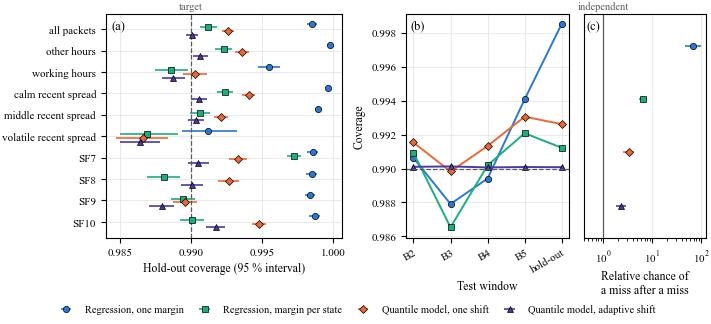

In [12]:
# Figure: where coverage fails, how it drifts across windows, and how the misses cluster (99 %), from the result files of this notebook
import paper_figures as pf
pf.use()
table = pd.read_csv("CV_Results/margin_calibration.csv", dtype={"group": str})
holdout = pd.read_csv("CV_Results/margin_holdout_states.csv", dtype={"group": str})
backtests = pd.read_csv("CV_Results/margin_backtests.csv", index_col=0)
windows = sorted(table.window.unique())
shown = {"reg pooled": ("Regression, one margin", "#2a78d6", "o"), "reg state table": ("Regression, margin per state", "#1baf7a", "s"),
         "q pooled": ("Quantile model, one shift", "#eb6834", "D"), "q ACI": ("Quantile model, adaptive shift", "#4a3aa7", "^")}
names = {("all", "all"): "all packets", ("hours", "0"): "other hours", ("hours", "1"): "working hours", ("spread", "0"): "calm recent spread",
         ("spread", "1"): "middle recent spread", ("spread", "2"): "volatile recent spread", ("SF", "7"): "SF7", ("SF", "8"): "SF8", ("SF", "9"): "SF9", ("SF", "10"): "SF10"}
fig, ax = plt.subplots(1, 3, figsize=(pf.PAGE, 3.3), gridspec_kw={"width_ratios": [1.45, 1, 0.75]}, layout="constrained")
for j, (method, (label, colour, marker)) in enumerate(shown.items()):
    h = holdout[holdout.method == method].set_index(["group_type", "group"]).loc[list(names)]
    y_pos = np.arange(len(names))[::-1] + (1.5 - j) * 0.17
    ax[0].errorbar(h.coverage, y_pos, xerr=[h.coverage - h.lo, h.hi - h.coverage], fmt=marker, color=colour, mec="black", elinewidth=1.2, capsize=0, label=label)
    c = table[(table.tau == 0.99) & (table.method == method) & (table.group_type == "all")].sort_values("window")
    ax[1].plot(range(len(c)), c.coverage, marker + "-", color=colour, mec="black")
    b = backtests.loc[method]
    ax[2].errorbar(b.ratio, 3 - j, xerr=[[b.ratio - b.lo], [b.hi - b.ratio]], fmt=marker, color=colour, mec="black", elinewidth=1.2, capsize=0)
ax[0].set_yticks(np.arange(len(names))[::-1], list(names.values()))
ax[0].set_xlabel("Hold-out coverage (95 % interval)")
ax[0].xaxis.set_major_locator(plt.MaxNLocator(4))
ax[0].axvline(0.99, color="0.35", lw=0.9, ls="--")
ax[0].text(0.99, 1.01, "target", transform=ax[0].get_xaxis_transform(), ha="center", va="bottom", fontsize=7.5, color="0.35")
ax[1].set_xticks(range(len(windows)), [f"B{w + 1}" if w < 9 else "hold-out" for w in windows], rotation=30, ha="right", rotation_mode="anchor")
ax[1].set_ylabel("Coverage")
ax[1].set_xlabel("Test window")
ax[1].axhline(0.99, color="0.35", lw=0.9, ls="--")
ax[2].set_xscale("log")
ax[2].axvline(1, color="0.35", lw=0.9)
ax[2].text(1, 1.01, "independent", transform=ax[2].get_xaxis_transform(), ha="center", va="bottom", fontsize=7.5, color="0.35")
ax[2].set_yticks([])
ax[2].set_ylim(-0.6, len(shown) - 0.4)
ax[2].set_xlabel("Relative chance of\na miss after a miss")
ax[2].set_xlim(left=0.4)
for a_, tag in zip(ax, "abc"):
    pf.panel(a_, tag)
fig.legend(*ax[0].get_legend_handles_labels(), loc="outside lower center", ncol=4)
fig.savefig("Figures/margin_calibration.png")
plt.show()

**Reading of the results, 99 % target.**

* **A pooled shift drifts with the regime.** One margin from all earlier validation packets covers between 98.8 and 99.4 % in the validation windows and 99.85 % on the hold-out, which has practically no SF11 or SF12 (33 packets) and is a summer window. In the four validation windows its worst state is always SF12, covered at 93.7 to 94.5 %, while every other spreading factor is covered at 99.5 % or more: the SF12 packets are pooled with the rest. Calibrated on the SF7-10 validation packets only, the regime of the hold-out, one margin lies 5.2 dB above the anchor for the LightGBM regression and 7.3 dB for the previous-hour mean, and 16.6 to 17.2 dB above the prediction of the learned static models, with hold-out coverages of 99.1 to 99.7 %; the regression's fixed margin then covers only 98.5 % in working hours, 97.7 % in the volatile third and 98.6 % at SF9.
* **Knowing the state is most of the gain.** A margin per group of spreading factor and working hours cuts the pinball loss of the regression on the hold-out from 87.6 to 65.3 per thousand, and adding the recent-spread tercile, a table of 36 margins, to 63.0. The mean margin above the anchor falls from 7.9 to 4.7 dB, and the hold-out coverage from 99.85 to 99.15 %.
* **The quantile model is sharper than the table, and not by much.** Against the 36-cell table its pinball loss is 4.1 lower per thousand, with an interval from 3.1 to 5.5, about 6.5 %. Its coverage in the volatile third is level with the table (difference 0.0 points, interval -0.2 to +0.1) and 0.8 points above the 12-cell table (interval +0.5 to +1.0). Conditional coverage therefore comes from knowing the state, by a table or by a model, not from the quantile model as such.
* **Adaptive conformal inference removes the drift.** Coverage is 99.0 % in every window for both base predictors, where the pooled shift moves between 98.8 and 99.85 %. In the window with the heaviest tail, validation fold 3, it lowers the pinball loss of the quantile model by 32 % (difference 41.7 per thousand, interval 10.4 to 86.3). On the hold-out it lowers the mean margin of the quantile model from 4.68 to 4.45 dB. Its states are covered at 98.7 to 99.2 %, the volatile third, working hours and SF9 being 0.1 to 0.3 points below the target.
* **Misses cluster less the more the margin knows.** The chance of a miss right after a miss, relative to after a covered packet, is 62 for the regression with one margin, 10 with the 12-cell table, 5.5 with the 36-cell table, 3.4 for the quantile model with one shift and 2.3 with the adaptive shift (interval 1.7 to 2.8). No method reaches independence. The Wald test of the misses on the previous miss and the state rejects for every method with half a million packets, so the effect sizes matter: the chance of a miss across the states ranges from 0 to 15 % for the regression with one margin and from 0.7 to 3.6 % for the quantile model with the adaptive shift, against a target of 1 %.
* **Settings.** A recency half-life of 7, 30 or 120 days and an adaptive step of the target gap divided by 100, 20 or 4 change the hold-out pinball loss by less than 2 %.
* **Recommendation.** With feedback from the received packets, the quantile model with the adaptive shift: exact coverage in every window, the lowest loss in four of five windows and tied in the fifth, the lowest clustering. Without feedback, the quantile model calibrated per state, or the 36-cell table, whose hold-out pinball loss is about 8 % higher.